In [21]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/parulpandey/palmer-archipelago-antarctica-penguin-data/penguins_lter.csv
/kaggle/input/datasets/parulpandey/palmer-archipelago-antarctica-penguin-data/penguins_size.csv


In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

In [23]:
df = pd.read_csv(
    "/kaggle/input/datasets/parulpandey/palmer-archipelago-antarctica-penguin-data/penguins_size.csv"
)

df.head()

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


In [24]:
features = [
    "culmen_length_mm",
    "culmen_depth_mm",
    "flipper_length_mm",
    "body_mass_g"
]

target = "species"

df_clean = df[features + [target]].copy()

df_clean.head()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,species
0,39.1,18.7,181.0,3750.0,Adelie
1,39.5,17.4,186.0,3800.0,Adelie
2,40.3,18.0,195.0,3250.0,Adelie
3,NaN,NaN,NaN,NaN,Adelie
4,36.7,19.3,193.0,3450.0,Adelie


In [25]:
le = LabelEncoder()

y = le.fit_transform(df_clean[target])

print("Classes:", le.classes_)
print("Encoded values:", np.unique(y))

Classes: ['Adelie' 'Chinstrap' 'Gentoo']
Encoded values: [0 1 2]


In [26]:
X = df_clean[features].values

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (275, 4)
X_test: (69, 4)
y_train: (275,)
y_test: (69,)


In [27]:

# Handle missing values using training data medians only

train_medians = np.nanmedian(X_train, axis=0)

X_train = np.where(np.isnan(X_train), train_medians, X_train)
X_test = np.where(np.isnan(X_test), train_medians, X_test)

print("Missing values in X_train:", np.isnan(X_train).sum())
print("Missing values in X_test:", np.isnan(X_test).sum())


Missing values in X_train: 0
Missing values in X_test: 0


In [28]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training data mean:", X_train.mean(axis=0))
print("Training data std:", X_train.std(axis=0))

Training data mean: [-2.77030923e-15  5.63428092e-15  3.73438654e-16  1.00929366e-16]
Training data std: [1. 1. 1. 1.]


In [29]:
def rbf_kernel(X1, X2, gamma=0.25):
    X1_sq = np.sum(X1**2, axis=1).reshape(-1, 1)
    X2_sq = np.sum(X2**2, axis=1).reshape(1, -1)

    distances = X1_sq + X2_sq - 2 * X1 @ X2.T
    distances = np.maximum(distances, 0)

    return np.exp(-gamma * distances)


gamma = 1 / X_train.shape[1]

K_train = rbf_kernel(X_train, X_train, gamma)
K_test = rbf_kernel(X_test, X_train, gamma)

print("K_train shape:", K_train.shape)
print("K_test shape:", K_test.shape)

K_train shape: (275, 275)
K_test shape: (69, 275)


In [30]:
classes = np.unique(y_train)

Y_train = np.where(
    y_train.reshape(-1, 1) == classes.reshape(1, -1),
    1,
    -1
)

print("Classes:", classes)
print("Y_train shape:", Y_train.shape)
print("Unique values:", np.unique(Y_train))

Classes: [0 1 2]
Y_train shape: (275, 3)
Unique values: [-1  1]


In [31]:
def predict_scores(K, alpha, bias):
    return K @ alpha + bias


def calculate_loss(K, Y, alpha, bias, lambda_reg):
    scores = predict_scores(K, alpha, bias)

    margins = 1 - Y * scores

    hinge_loss = np.maximum(0, margins).mean()

    regularization = 0.5 * lambda_reg * np.sum(
        alpha * (K @ alpha)
    )

    total_loss = hinge_loss + regularization

    return total_loss

In [32]:
learning_rate = 0.001
epochs = 500
lambda_reg = 0.01

beta = 0.9
epsilon = 1e-8

n_samples = K_train.shape[0]
n_classes = Y_train.shape[1]

alpha = np.zeros((n_samples, n_classes))
bias = np.zeros(n_classes)

squared_grad_alpha = np.zeros_like(alpha)
squared_grad_bias = np.zeros_like(bias)

loss_history = []

print("Learning Rate:", learning_rate)
print("Epochs:", epochs)
print("Beta:", beta)
print("Alpha shape:", alpha.shape)
print("Bias shape:", bias.shape)

Learning Rate: 0.001
Epochs: 500
Beta: 0.9
Alpha shape: (275, 3)
Bias shape: (3,)


In [33]:
momentum = 0.9

velocity_alpha = np.zeros_like(alpha)
velocity_bias = np.zeros_like(bias)

print("Momentum:", momentum)
print("Velocity Alpha shape:", velocity_alpha.shape)
print("Velocity Bias shape:", velocity_bias.shape)

Momentum: 0.9
Velocity Alpha shape: (275, 3)
Velocity Bias shape: (3,)


In [34]:
for epoch in range(epochs):

    scores = predict_scores(K_train, alpha, bias)

    margins = 1 - Y_train * scores

    active = (margins > 0).astype(float)

    grad_alpha = -(K_train.T @ (Y_train * active)) / Y_train.size
    grad_alpha += lambda_reg * (K_train @ alpha)

    grad_bias = -(Y_train * active).sum(axis=0) / Y_train.size

    # RMSProp: Update squared gradients
    squared_grad_alpha = (
        beta * squared_grad_alpha
        + (1 - beta) * (grad_alpha ** 2)
    )

    squared_grad_bias = (
        beta * squared_grad_bias
        + (1 - beta) * (grad_bias ** 2)
    )

    # RMSProp: Adaptive updates
    update_alpha = learning_rate * grad_alpha / (
        np.sqrt(squared_grad_alpha) + epsilon
    )

    update_bias = learning_rate * grad_bias / (
        np.sqrt(squared_grad_bias) + epsilon
    )

    # Momentum
    velocity_alpha = momentum * velocity_alpha - update_alpha
    velocity_bias = momentum * velocity_bias - update_bias

    alpha += velocity_alpha
    bias += velocity_bias

    loss = calculate_loss(
        K_train, Y_train, alpha, bias, lambda_reg
    )

    loss_history.append(loss)

    if (epoch + 1) % 50 == 0:
        print(f"Epoch {epoch + 1}/{epochs}, Loss: {loss:.6f}")

Epoch 50/500, Loss: 0.190226
Epoch 100/500, Loss: 0.180151
Epoch 150/500, Loss: 0.179617
Epoch 200/500, Loss: 0.178950
Epoch 250/500, Loss: 0.180268
Epoch 300/500, Loss: 0.179549
Epoch 350/500, Loss: 0.179217
Epoch 400/500, Loss: 0.179391
Epoch 450/500, Loss: 0.179628
Epoch 500/500, Loss: 0.178130


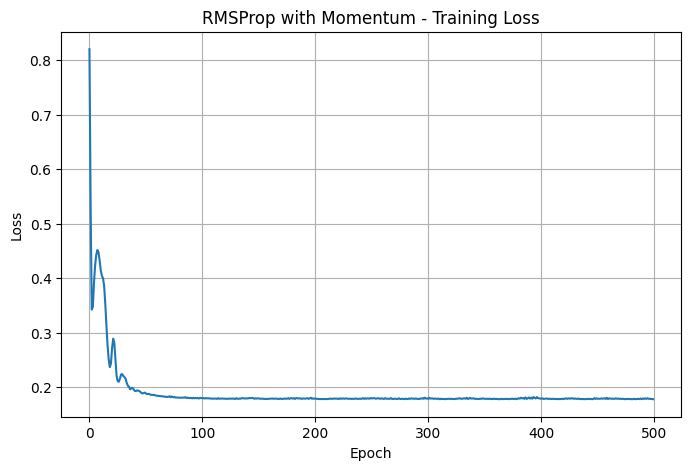

In [35]:
plt.figure(figsize=(8, 5))
plt.plot(loss_history)

plt.title("RMSProp with Momentum - Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)

plt.show()

In [36]:
test_scores = predict_scores(K_test, alpha, bias)

y_pred = classes[np.argmax(test_scores, axis=1)]

accuracy = accuracy_score(y_test, y_pred)

print("Test Accuracy:", accuracy)
print(f"Test Accuracy (%): {accuracy * 100:.2f}%")

Test Accuracy: 0.9855072463768116
Test Accuracy (%): 98.55%


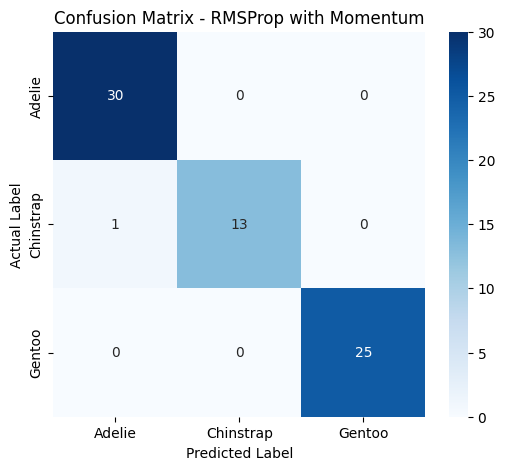

In [37]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=le.classes_,
    yticklabels=le.classes_
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix - RMSProp with Momentum")

plt.show()

In [38]:
print("Classification Report - RMSProp with Momentum")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=le.classes_
    )
)

Classification Report - RMSProp with Momentum
              precision    recall  f1-score   support

      Adelie       0.97      1.00      0.98        30
   Chinstrap       1.00      0.93      0.96        14
      Gentoo       1.00      1.00      1.00        25

    accuracy                           0.99        69
   macro avg       0.99      0.98      0.98        69
weighted avg       0.99      0.99      0.99        69

